# Rolling CAPM and parameter stability

Estimate IBM's sensitivity to the US stock market, first over the full sample
and then in rolling windows of **60 months**. The focus is how to interpret
beta, its uncertainty and changes across windows.

The estimation sample contains **312 monthly returns, January 2000–December 2025**.
All data are included locally; no download or API key is needed to run the notebook.

Data Sources:

- [Alpha Vantage](https://www.alphavantage.co/documentation/): IBM monthly
  prices adjusted for dividends and splits.
- [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html):
  the broad, value-weighted US market excess return (`Mkt-RF`) and the monthly
  risk-free return (`RF`). The market is not an individual stock or the S&P 500.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "OLS"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: OLS


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

## Data

In [3]:
# Month-end labels align the two sources. The stock's actual trading date
# is retained in Stock_observation_date. December 1999 is a price base only.
levels = pd.read_csv(DATA_DIR / "monthly_capm_data.csv", parse_dates=["date"])
levels = levels.set_index("date").sort_index()
months = levels.index.to_period("M")
expected_months = pd.period_range("1999-12", "2025-12", freq="M")
if not months.equals(expected_months):
    raise ValueError("Missing or duplicated months: inspect the CSV.")
if levels.isna().any().any() or not levels["Stock_adj_close"].gt(0).all():
    raise ValueError("Missing data or invalid prices: inspect the CSV.")

# Adjusted prices include dividends and splits: do not add dividends again.
# Use simple returns for both the stock and the French market factor.
levels["Stock_return"] = levels["Stock_adj_close"].pct_change(fill_method=None)
levels["Stock_excess"] = levels["Stock_return"] - levels["RF"]

# RF is already a monthly return, so do not divide by 12.
# Market_excess is already Mkt-RF, so do not subtract RF a second time.
# Express both regression variables in percent (1 means one percentage point).
data = 100 * levels[["Stock_excess", "Market_excess"]].iloc[1:].copy()
if data.isna().any().any():
    raise ValueError("Missing estimation observations: inspect the input data.")
print(f"Estimation sample: {len(data)} months, {data.index[0]:%b %Y}–{data.index[-1]:%b %Y}")
display(data.head().round(3))

Estimation sample: 312 months, Jan 2000–Dec 2025


,Stock_excess,Market_excess
date,,
2000-01-31,3.650,-4.74
2000-02-29,-8.801,2.46
2000-03-31,14.732,5.21
2000-04-30,-6.264,-6.39
2000-05-31,-4.144,-4.39


## The CAPM regression

For stock return $R_t$, market return $R_{m,t}$ and risk-free return $R_{f,t}$,
estimate the standard excess-return regression:

$$R_t-R_{f,t}=\alpha+\beta(R_{m,t}-R_{f,t})+u_t.$$

Beta is the fitted change in IBM's excess return associated with a
one-percentage-point increase in the market excess return. A beta of 1 means
market-like sensitivity; a beta above 1 means greater sensitivity. Alpha is
the fitted monthly excess return when the market excess return is zero.
Alpha is measured in percent per month; beta has no units.

Use **HAC standard errors with 3 monthly lags** to allow for heteroskedasticity
and serial correlation. The lag choice is a teaching specification, rather than
a guarantee that all dependence is captured. HAC changes inference, not the
OLS coefficients, and does not fix omitted variables or establish causality.

In [4]:
HAC_LAGS = 3

def fit_capm(sample):
    X = sm.add_constant(sample[["Market_excess"]], has_constant="add")
    ols = sm.OLS(sample["Stock_excess"], X, missing="raise").fit()
    # Bartlett weights, finite-sample correction and approximate t inference.
    hac = ols.get_robustcov_results(
        cov_type="HAC", maxlags=HAC_LAGS, use_correction=True, use_t=True
    )
    return ols, hac

full_ols, full_hac = fit_capm(data)
ci = full_hac.conf_int(alpha=0.05)
full_results = pd.DataFrame({
    "Estimate": full_hac.params,
    "HAC SE": full_hac.bse,
    "t statistic": full_hac.tvalues,
    "p-value (H0: coefficient = 0)": full_hac.pvalues,
    "95% lower": ci[:, 0],
    "95% upper": ci[:, 1]
}, index=["Alpha (% per month)", "Beta"])
with pd.option_context("display.float_format", "{:.4g}".format):
    display(full_results)
print(f"R-squared: {full_ols.rsquared:.3f} | Observations: {int(full_ols.nobs)}")

,Estimate,HAC SE,t statistic,p-value (H0: coefficient = 0),95% lower,95% upper
Alpha (% per month),0.07431,0.3075,0.2416,0.8092,-0.5308,0.6794
Beta,0.9497,0.1024,9.276,3.124e-18,0.7482,1.151


R-squared: 0.352 | Observations: 312


The beta p-value tests **zero market sensitivity**, rather than whether beta
equals 1. A small alpha p-value would indicate evidence against zero alpha in
this specification; it would not by itself demonstrate skill or validate the CAPM.
$R^2$ measures the share of sample variation in IBM's excess return explained
by the fitted regression. A significant beta does not mean the market explains
every monthly movement.

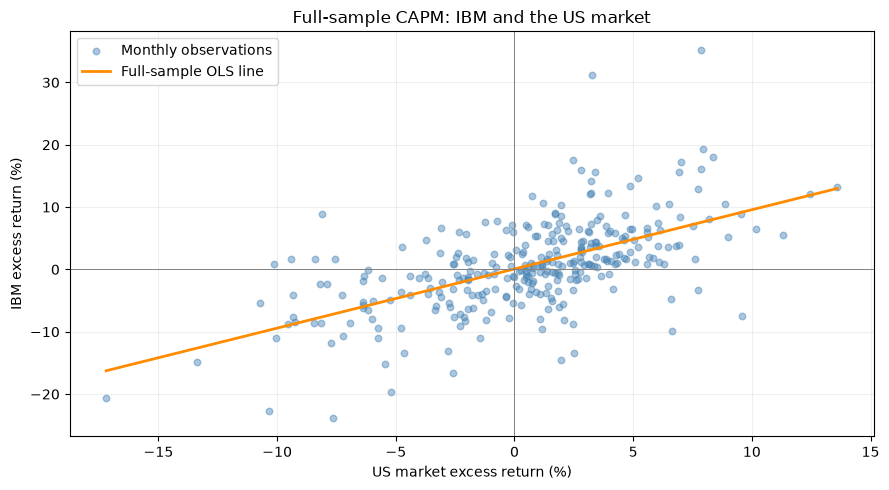

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(data["Market_excess"], data["Stock_excess"], alpha=0.45, s=22,
           color="steelblue", label="Monthly observations")
grid = np.linspace(data["Market_excess"].min(), data["Market_excess"].max(), 150)
ax.plot(grid, full_hac.params[0] + full_hac.params[1] * grid,
        color="darkorange", linewidth=2, label="Full-sample OLS line")
ax.axhline(0, color="grey", linewidth=0.7)
ax.axvline(0, color="grey", linewidth=0.7)
ax.set(xlabel="US market excess return (%)", ylabel="IBM excess return (%)",
       title="Full-sample CAPM: IBM and the US market")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Rolling windows

Re-estimate the same regression each month using the most recent **60 monthly
observations**. The first window is January 2000–December 2004; the next window
drops January 2000 and adds January 2005. Each estimate is dated at the end of
its window, giving **253 estimates** through December 2025.

The fitted equation in window $j$ is
$R_t-R_{f,t}=\hat\alpha_j+\hat\beta_j(R_{m,t}-R_{f,t})+\hat u_t$.
Here $\hat\beta_j$ is a market sensitivity, with the same interpretation as
the full-sample beta. Each window has its own intercept as well as its own slope.

In [6]:
WINDOW = 60
records = []

# Include both the first and the last complete window.
for end in range(WINDOW, len(data) + 1):
    sample = data.iloc[end - WINDOW:end]
    ols, hac = fit_capm(sample)
    interval = hac.conf_int(alpha=0.05)
    records.append({
        "end": sample.index[-1], "start": sample.index[0], "n": int(ols.nobs),
        "alpha": hac.params[0], "beta": hac.params[1],
        "beta SE": hac.bse[1], "beta lower": interval[1, 0],
        "beta upper": interval[1, 1], "R-squared": ols.rsquared
    })

rolling = pd.DataFrame(records).set_index("end")
print(f"Rolling estimates: {len(rolling)} | Months in each window: {WINDOW}")

Rolling estimates: 253 | Months in each window: 60


## Beta and uncertainty

The shaded band is a **pointwise 95% confidence interval** for each window's
beta, using HAC standard errors and an approximate $t$ reference distribution.
It is an interval for a coefficient, rather than a prediction interval for
future stock returns. The full-sample beta provides a reference for the average
relationship across the entire period.

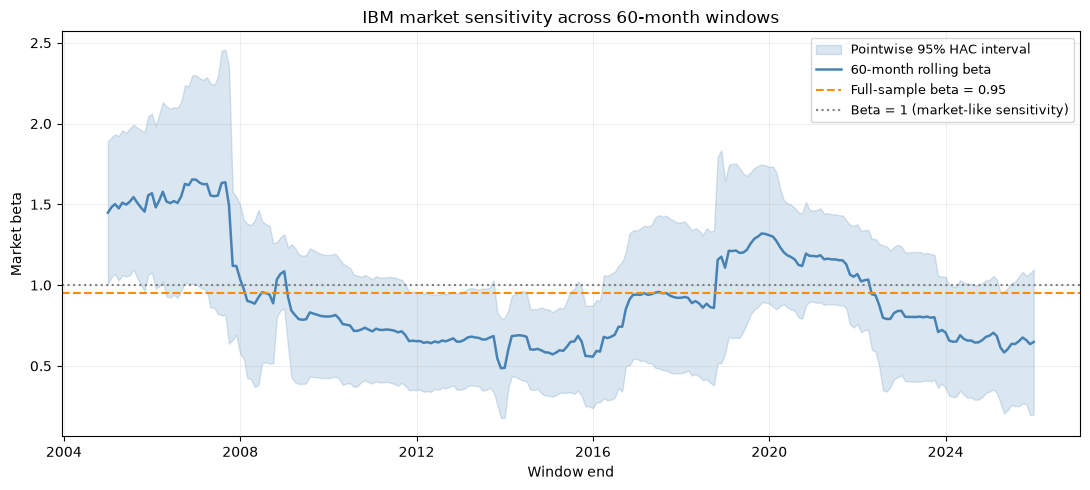

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(rolling.index, rolling["beta lower"].to_numpy(),
                rolling["beta upper"].to_numpy(), color="steelblue", alpha=0.2,
                label="Pointwise 95% HAC interval")
ax.plot(rolling.index, rolling["beta"], color="steelblue", linewidth=1.8,
        label="60-month rolling beta")
ax.axhline(full_hac.params[1], color="darkorange", linestyle="--", linewidth=1.5,
           label=f"Full-sample beta = {full_hac.params[1]:.2f}")
ax.axhline(1, color="grey", linestyle=":", label="Beta = 1 (market-like sensitivity)")
ax.set(xlabel="Window end", ylabel="Market beta",
       title="IBM market sensitivity across 60-month windows")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Comparing windows

Compare three windows ending in December 2004, 2014 and 2025. Each row uses
five years of data. The estimates describe an average relationship **within
that window**, rather than the relationship in its final month alone.

In [8]:
selected = rolling.loc[pd.to_datetime(["2004-12-31", "2014-12-31", "2025-12-31"])].copy()
selected.index.name = "Window end"
selected["start"] = selected["start"].dt.strftime("%b %Y")
selected = selected.rename(columns={"start": "Window start", "n": "Months",
                                    "alpha": "Alpha (% per month)", "beta": "Beta",
                                    "beta SE": "HAC beta SE", "beta lower": "95% lower",
                                    "beta upper": "95% upper"})
with pd.option_context("display.float_format", "{:.3f}".format):
    display(selected)

,Window start,Months,Alpha (% per month),Beta,HAC beta SE,95% lower,95% upper,R-squared
Window end,,,,,,,,
2004-12-31,Jan 2000,60,0.557,1.448,0.221,1.006,1.890,0.472
2014-12-31,Jan 2010,60,-0.152,0.582,0.133,0.315,0.849,0.246
2025-12-31,Jan 2021,60,1.294,0.648,0.224,0.199,1.097,0.160


Moving estimates suggest that a single full-sample beta may hide differences
across periods. They can also reflect sampling noise, influential observations
or changes in market-return dispersion. Wider intervals indicate less precise
estimates; a visible change alone is not a formal test of a structural break.

Adjacent windows share **59 of their 60 observations**, so their estimates are
not independent. The bands are not a simultaneous confidence band for the entire
path, and overlapping or non-overlapping intervals do not replace a direct test
of coefficient equality. The 60-month window balances recency against precision:
shorter windows respond faster but generally produce noisier estimates.